# 02 · Likelihood & Covariance Checks

Validates the internals of the likelihood/covariance machinery (and the fixes
applied to `interpret.py`):

1. the **whitened residual** handed to the optimizer satisfies Σrᵢ² = χ²;
2. the **Fisher** error agrees with an independent **profile-likelihood** error;
3. the reported error correctly **scales with √(χ²/dof)** for a poor fit;
4. the **χ²/dof distribution** for a good fit is centred where it should be.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import mstest_utils as mu          # shared helpers (lives in metascience/python/)
import interpret, cosmology, consensus

np.random.seed(0)
plt.rcParams['figure.figsize'] = (8, 4.5)

## 1. Whitened-residual identity:  Σ (whitened residual)² = χ²

In [2]:
_, interp, _ = mu.run_fit(truth_name='CosineCosmology', interp_name='CosineCosmology', seed=110)
cosmo = interp.cosmology
x = np.concatenate([interp.best_fit_cosmological_parameters,
                    interp.best_fit_nuisance_parameters,
                    interp.best_fit_systematics_parameters])
model = cosmo.generate_model_data_vector(interp.times, x[:cosmo.n_parameters])
model = interp._add_systematics(model, parameters=x[cosmo.n_parameters:])
delta = model - interp.measured_data_vector
whitened = interp.whitening_matrix.T @ delta
print('sum(whitened^2) :', float(np.sum(whitened**2)))
print('delta^T Cinv delta:', float(delta @ (interp.inverse_covariance @ delta)))
print('match           :', np.isclose(np.sum(whitened**2), delta @ (interp.inverse_covariance @ delta)))

Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49922845 1.9986991  0.00209384 0.00816035]


sum(whitened^2) : 499.3107525368831
delta^T Cinv delta: 499.310752536883
match           : True


## 2. Fisher vs profile likelihood (mismatched model)

Fit a `CosineCosmology` model to `DampedDrivenOscillator` data (a poor fit).
The reported error now carries the χ²/dof inflation, so we strip that back off
to compare the *pure Fisher curvature* against the profile-likelihood error.
They should agree to a few percent — confirming the Fisher math is right and
the only adjustment is the goodness-of-fit rescaling.

In [3]:
_, interp, _ = mu.run_fit(truth_name='DampedDrivenOscillatorCosmology',
                          interp_name='CosineCosmology', times='times_A.txt', seed=110)
c2d = mu.chi2_per_dof(interp)
reported = mu.cosmo_errors(interp)[0]
raw_fisher = reported / np.sqrt(c2d)          # undo the chi2/dof rescaling
prof = mu.profile_sigma(interp, which=0)      # independent delta-chi2=1 scan

print(f'chi2/dof                 : {c2d:.2f}')
print(f'reported sigma (rescaled): {reported:.5f}')
print(f'raw Fisher sigma         : {raw_fisher:.5f}')
print(f'profile-likelihood sigma : {prof:.5f}')
print(f'Fisher / profile         : {raw_fisher/prof:.3f}   (ideal ~1)')
print(f'rescale factor sqrt(c2d) : {np.sqrt(c2d):.2f}')

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 1.06309238  0.46106078 -3.56997003 -0.01934474]


chi2/dof                 : 15.08
reported sigma (rescaled): 0.00877
raw Fisher sigma         : 0.00226
profile-likelihood sigma : 0.00221
Fisher / profile         : 1.021   (ideal ~1)
rescale factor sqrt(c2d) : 3.88


## 3. χ²/dof distribution for a correct model
Should scatter around 1 (dof ≈ Ndata − Nparams).

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.50134545  1.99866842 -0.00582651  0.00655514]


Initial guess:[0.5 2.  0.  0. ]
best fit:[5.00029301e-01 1.99661336e+00 1.17245384e-03 1.89360597e-02]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.5008023   1.99945709 -0.00337086 -0.01627496]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 5.00584308e-01  2.00163543e+00 -1.68497900e-03 -1.04961401e-03]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 5.00231757e-01  1.99706962e+00 -1.51595010e-04  6.42293744e-03]


Initial guess:[0.5 2.  0.  0. ]
best fit:[ 0.50061744  1.99917697 -0.00399853 -0.00651018]


... (71 outputs left out)

Initial guess:[0.5 2.  0.  0. ]
best fit:[ 4.99839561e-01  1.99843476e+00  2.30958560e-04 -1.35477032e-02]


Initial guess:[0.5 2.  0.  0. ]
best fit:[0.49954317 1.9983019  0.00223633 0.01159842]


Initial guess:[0.5 2.  0.  0. ]
best fit:[4.99471955e-01 2.00032560e+00 2.23149029e-04 1.34290633e-02]


mean chi2/dof = 1.005  (ideal ~1)


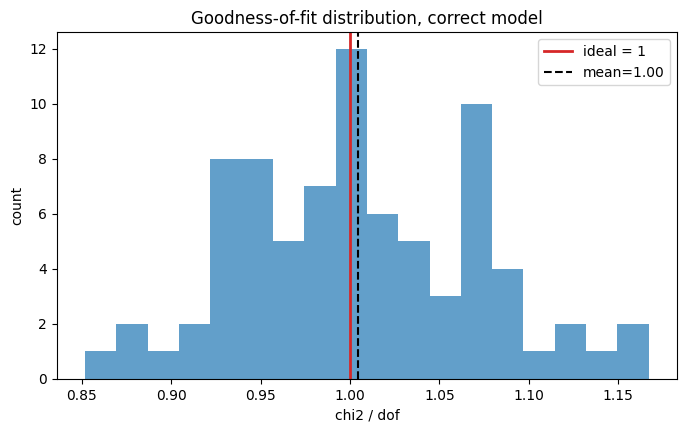

In [4]:
M = 80
c2d_vals = []
for s in range(M):
    _, it, _ = mu.run_fit(truth_name='CosineCosmology', interp_name='CosineCosmology',
                          noise=0.03, seed=2000+s)
    c2d_vals.append(mu.chi2_per_dof(it))
c2d_vals = np.array(c2d_vals)
print(f'mean chi2/dof = {c2d_vals.mean():.3f}  (ideal ~1)')
plt.hist(c2d_vals, bins=18, alpha=.7)
plt.axvline(1.0, color='C3', lw=2, label='ideal = 1')
plt.axvline(c2d_vals.mean(), color='k', ls='--', label=f'mean={c2d_vals.mean():.2f}')
plt.xlabel('chi2 / dof'); plt.ylabel('count'); plt.legend()
plt.title('Goodness-of-fit distribution, correct model');

### Reading this
The whitened-residual identity and the Fisher/profile agreement (~1) confirm
the covariance machinery is internally consistent. The mean χ²/dof near 1
confirms the noise model and dof bookkeeping line up. If (2) drifts away from
1 for a *different* cosmology, that cosmology's finite-difference Fisher step
may need tuning.